# OCR with EasyOCR on the midterm paper

Install: `pip install easyocr` (models download on the first run)

In [1]:
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import easyocr
import pytesseract

reader = easyocr.Reader(["en"], gpu=False, verbose=False)


def word_acc(pred, truth):
    """Share of the true words found, in any order."""
    found = Counter(pred.split()) & Counter(truth.split())
    return sum(found.values()) / len(truth.split())


def read(img, **kwargs):
    return " ".join(reader.readtext(np.asarray(img), detail=0, **kwargs))


/Users/nurislamaliyev/Documents/University/Deep-Learning/Deep_Learning_Course/.venv/lib/python3.14/site-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


## The photo
The same photo as in the Tesseract notebook, scored the same way.

(2560, 1920)


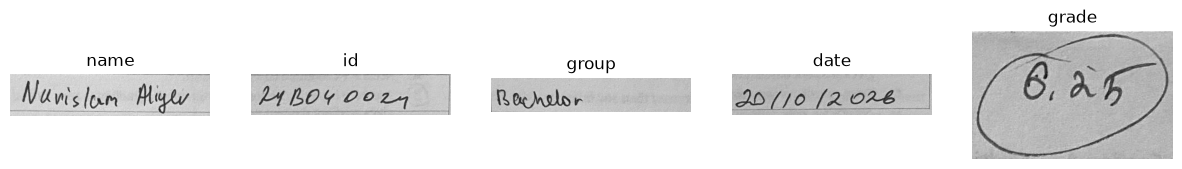

In [2]:
import re
import cv2

page = cv2.imread("midterm.jpg", cv2.IMREAD_GRAYSCALE)
print(page.shape)

# printed text on the page, typed by hand and used as ground truth (handwriting is checked by eye)
TRUTH = """Kazakh-British Technical University School of IT and Engineering
CSCI1409 Deep Learning Fall 2026-2027 Midterm Examination
Week 8 attestation Covers Weeks 1-7 40 questions + 1 bonus 10 points 120 minutes
Full name Student ID Group Date Instructions
Section A (Questions 1-10): multiple choice, 0.15 points each. Circle one letter for each question.
Section B (Questions 11-20): calculations, 0.35 points each. Show your working in the box a correct
method earns partial credit even if the final number is wrong. Round to 3 decimal places; ln is the natural logarithm.
Section C (Questions 21-40): open questions, 0.25 points each. Answer concisely in the lined space. Bullet
points, equations and corrected code are acceptable; there is no minimum length.
Bonus (Question 41): optional, +0.25 points on top of the 10-point total (maximum score 10.25).
Short, precise answers can earn full marks. If you get stuck on a question, move on and come back to it later.
Closed book. A non-programmable calculator is allowed. Phones, notes, laptops, smartwatches and AI tools
are not allowed. Academic integrity
Copying, using unauthorised materials or devices, or communicating with other students during the exam is a
violation of KBTU academic policy and will be reported. All answers must be your own work.
For instructor use Section Questions Points Score A Multiple choice 1-10 1.50 B Calculations 11-20 3.50
C Open questions 21-40 5.00 Total 40 10.00 Bonus (optional) 41 +0.25"""


def norm(text):
    """Lower case and drop punctuation, so scoring looks at the words themselves."""
    return re.sub(r"[^\w\s.+-]", "", text.lower().replace("–", "-").replace("—", " "))


def score(text):
    return word_acc(norm(text), norm(TRUTH))


def adaptive(img):
    return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)


def clahe(img):
    return cv2.createCLAHE(2.0, (8, 8)).apply(img)


versions = {"original": page, "clahe": clahe(page), "adaptive": adaptive(page)}

# handwriting regions, in pixels of the original 1920x2560 photo
crops = {
    "name":  page[745:840, 500:960],
    "id":    page[745:840, 1225:1690],
    "group": page[835:915, 500:960],
    "date":  page[835:930, 1225:1690],
    "grade": page[240:470, 1350:1710],
}

fig, axes = plt.subplots(1, 5, figsize=(15, 2.5))
for ax, (name, crop) in zip(axes, crops.items()):
    ax.imshow(crop, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.show()


## Preprocessing on the photo

In [3]:
# the full photo is too heavy for CRAFT on CPU, so detection runs on a smaller copy
SCALE = 0.6


def small(img):
    return cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)


for name, img in versions.items():
    start = time.time()
    text = read(small(img), paragraph=True, canvas_size=1280)
    print(f"{name:<12}{score(text):.2f}   {time.time() - start:.1f}s")


/Users/nurislamaliyev/Documents/University/Deep-Learning/Deep_Learning_Course/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


original    0.91   9.8s


clahe       0.91   9.9s


adaptive    0.91   7.0s


## Full output

In [4]:
print(read(small(page), paragraph=True, canvas_size=1280))


6,46 Kazakh-British Technical Universily Schoo of IT and Engineering CSCI1409 Deep Learning Fall 2026-2027 Midterm Examination Week 8 attestation Covers Weeks 1-7 . 40 questions 1 bonus 10 points 120 minutes Full name Nuvislun Aglv Student ID Rechebor Date 24 1ov 0027 30 (10-(2 026 Group Instructions Section A (Questions 1-10): multiple choice; 0.15 points each: Circle one letter for each question_ Section B (Questions 11-20): calculations, 0.35 points each: Show your working in the box correct method earns partial credit even if the final number is wrong: Round to 3 decimal places; In is the natural logarithm. Section € (Questions 21-40): open questions, 0.25 points each. Answer concisely in the lined space. Bullet points, equations and corrected code are acceptable; there is no minimum length. Bonus (Question 41): optional, +0.25 points on top of the 10-point total (maximum score 10.25). Short, precise answers can earn full marks_ If you get stuck on question, move on and come back t

## Boxes
Green is confidence above 0.8, red is below.

66 boxes, mean confidence 0.83, below 0.8: 25


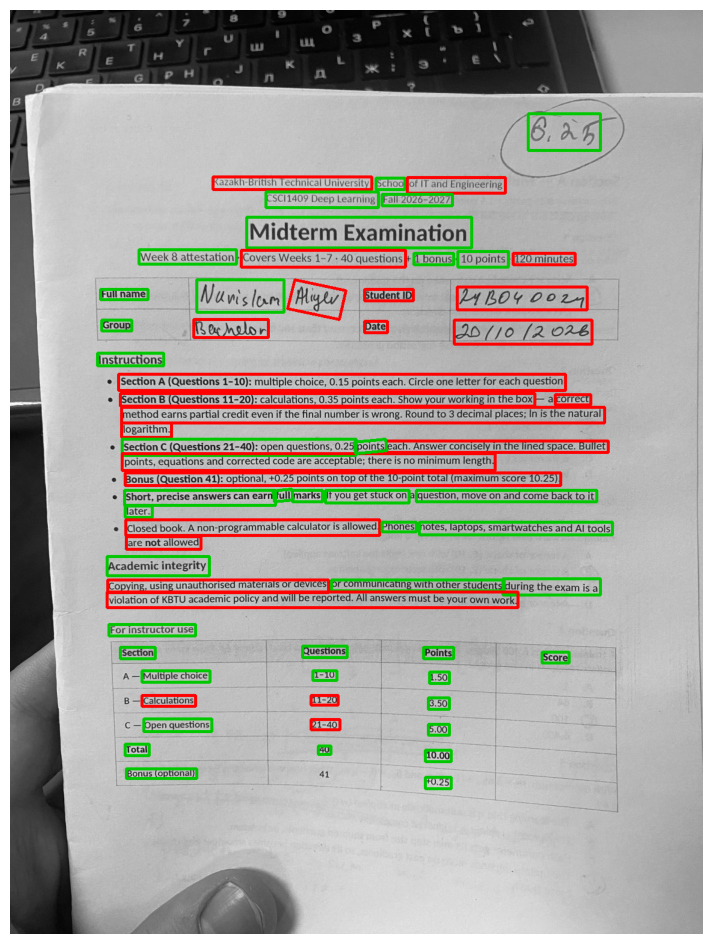

In [5]:
found = reader.readtext(small(page), canvas_size=1280)
canvas = cv2.cvtColor(small(page), cv2.COLOR_GRAY2RGB)
for box, text, conf in found:
    cv2.polylines(canvas, [np.array(box, dtype=np.int32)], True, (0, 200, 0) if conf > 0.8 else (255, 0, 0), 3)

confs = [c for _, _, c in found]
print(f"{len(found)} boxes, mean confidence {np.mean(confs):.2f}, below 0.8: {sum(c <= 0.8 for c in confs)}")
plt.figure(figsize=(9, 12))
plt.imshow(canvas)
plt.axis("off")
plt.show()


## Handwriting

In [6]:
for name, crop in crops.items():
    print(f"{name:<7}", reader.readtext(crop, detail=0))


name    ['Nuwislun', 'Mwskv']
id      ['24 Bov 00271']
group   ['Rechebor']


date    ['30(l0_(2 0xe']
grade   ['6, 46']


## EasyOCR vs Tesseract on the photo

In [7]:
print(f"{'':<12}{'word acc':>9}{'time':>8}")
for name, fn in {"tesseract": lambda: pytesseract.image_to_string(page, config="--psm 3"),
                 "easyocr": lambda: read(small(page), paragraph=True, canvas_size=1280)}.items():
    start = time.time()
    text = fn()
    print(f"{name:<12}{score(text):>9.2f}{time.time() - start:>7.1f}s")


             word acc    time


tesseract        0.94    1.1s


/Users/nurislamaliyev/Documents/University/Deep-Learning/Deep_Learning_Course/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


easyocr          0.91    8.3s


## Difference between Tesseract and EasyOCR

| | Tesseract | EasyOCR |
|---|---|---|
| How it works | Finds the page layout, then an LSTM reads each line | CRAFT network finds text boxes, then a CRNN reads each box |
| Best at | Clean printed pages | Noisy or rotated images, multiple languages |
| Midterm printed text (word accuracy) | 0.94 | 0.91 (on a 60% size copy) |
| Midterm time on CPU | 1.0 s | 7.4 s |
| Midterm handwriting | Almost nothing readable | Closer, but still wrong |

Neither model is made for handwriting: the grade 6,25 came out as `6, 46` in EasyOCR and empty in Tesseract.